<img src="logos/Logo_de_la_Facultad_Experimental_de_Ciencia_y_Tecnología.svg.png"
     width="250"
     style="display: block; margin-left: auto; margin-right: auto;">

<div align="center">

**UNIVERSIDAD DE CARABOBO**
Facultad Experimental de Ciencia y Tecnología
Departamento de Computación
Aprendizaje Automatizado

# Minecraft Composting — Data Preparation and Feature Engineering
### Assignment 2: from the EDA to a reproducible, leakage-safe pipeline

</div>

**Professor:** Álvaro Espinoza &nbsp;|&nbsp; **Students:** Jesús Redondo (31499459), Joshtin Mejías (31071016) &nbsp;|&nbsp; **Year:** 2026

---

This notebook turns the findings of the EDA (`01_eda.ipynb`) into a data-preparation process that is **reproducible**
(it runs from the 16 raw CSV files after *Restart Kernel → Run All*) and **safe against data leakage** (everything that
learns from data is fitted on the training sessions only). It does **not** train, compare or tune models; that belongs
to the next notebook.

# 1. Purpose and Problem Context

**The task.** In Minecraft, a *composter* turns organic items into bone meal: each item inserted may raise the
compost level by one, with an item-specific chance; after 7 level increases the composter is ready. The project
question is:

> *Given a single composting attempt, predict whether the item being inserted will raise the composter's level.*

| Element | Definition |
|---|---|
| **Original unit (raw files)** | one complete **session** for one material: items inserted into an empty composter until it is ready. The raw data stores only its length `items_used` = N. |
| **Modeling unit of observation** | one **attempt** = one item insertion, obtained by expanding each session into N rows. |
| **Target** | `level_increased` — `1` if the attempt raised the level, `0` otherwise (binary classification). |
| **What a prediction represents** | the probability that inserting *this* item *now* raises the composter's level. |
| **Prediction timestamp** | immediately **before** the current item is inserted. |
| **Generalization scenario** | **new sessions of the 16 known materials** (not unseen materials; not new attempts of sessions already seen). |

**Information available at the prediction timestamp**

| Column / information | Available? | Use |
|---|---|---|
| `material` (item being inserted) | Yes — the player chooses it | **feature** (and source of derived features) |
| composter is empty (level 0) | Yes — the level is visible | **feature** `composter_empty`, derived from `attempt_number == 1` |
| `attempt_number` > 1 / current level > 0 | Yes in reality, but **synthetic** in this dataset (order inside a session was not recorded) | **excluded** |
| `items_used` (final session length) and anything derived from it | **No** — known only when the session ends | **excluded** (future information) |
| per-material outcome statistics (chance, tiers) | Only if learned from **training** sessions | features learned inside the pipeline, train only |
| `trial_id`, `session_id` | identifiers, not measurements | **excluded** as features; `session_id` is used only to keep sessions intact in the split |

# 2. Relevant EDA Findings

Only the findings that drive a preparation decision are repeated here (details and evidence in `01_eda.ipynb`):

1. **Clean structure.** 16 files × 3,000 sessions, one integer column each, no missing values, no duplicated keys,
   `items_used ≥ 7` always. No rare categories: every material has exactly 3,000 sessions.
2. **Two granularities.** The raw data is per session; the task is per attempt. Counts of successes (7) and failures
   (N − 7) per session are *derivable*; the *order* of the middle outcomes is **not observed** — any expansion is one
   synthetic realization compatible with the counts.
3. **Mechanism.** The first item inserted into an **empty** composter always succeeds; the other 6 increases are random
   with the item's chance. Formal tests (nested likelihood-ratio test, chi-square goodness of fit, agreement with the
   documented chances) reject "7 random increases". Per-material chances are therefore estimated as
   $\hat p_m = 6n_m / \sum_s (N_{m,s} - 1)$ ≈ 0.85 / 0.65 / 0.50 / 0.30.
4. **Material dominates.** Materials form 4 well-separated tiers. `probability_tier` keeps ≈ 100% of the in-sample
   eta-squared of `material`, but it is built from outcome statistics on all data, so it is only a *candidate* and must
   be re-learned on training data.
5. **Redundancy.** `is_seed` is a deterministic function of `material` and adds nothing within tiers (Cramér's V 0.745
   with the tier). `items_used`, `log_items_used` and `quick_fill_*` describe the finished session.
6. **Class balance.** At the attempt level the target is ≈ 48% / 52%; ≈ 6.9% of attempts are into an empty composter
   (always successful), the rest succeed ≈ 44.5% of the time.
7. **One local anomaly.** `Sugar Cane` sessions with `trial_id` 339–398 (60 sessions) behave like a 30% material
   instead of 50% — probably a recording error, not confirmable from the data.
8. **No drift** between sessions with respect to recording order (outside that stretch), so a random (non-temporal)
   split of sessions is appropriate.

# 3. From EDA Findings to Preparation Decisions

| # | EDA finding | Evidence (EDA) | Decision | Justification |
|---|---|---|---|---|
| D1 | Raw data per session; task per attempt | §4, §8 granularity analysis | **Split sessions first** (80/20), then expand each partition to attempts | Attempts of one session share a fixed total (7 successes); splitting attempts would put parts of the same session in train and test |
| D2 | No temporal drift between sessions | §6 order check, block check | Random split of sessions, **stratified by material**, seed 42 | No chronological structure to respect; stratification keeps the 16 materials equally represented in both sets |
| D3 | Order of middle outcomes is synthetic | §8 observed / derivable / synthetic table | **Exclude `attempt_number`**; keep only its non-synthetic part (`== 1`) | Any feature depending on the reconstructed order would be fabricated |
| D4 | First addition into an empty composter always succeeds | §8 LRT, chi-square, documented chances | Create **`composter_empty`** (boolean rule) | Real mechanism, visible to the player before inserting |
| D5 | `items_used` known only after the session | §1 prediction timestamp table | **Exclude** `items_used`, `log_items_used`, `quick_fill_*` | Future information → leakage |
| D6 | `material`: 16 balanced levels, no rare or invalid labels | §6 cardinality, §7, §10 | **One-hot encode** `material`, `handle_unknown="ignore"` | Low cardinality; an unexpected label must not crash the pipeline |
| D7 | 4 tiers capture almost all between-material variance, but are built from outcomes | §10 eta², boxplots; PR #1 feedback | Create **`probability_tier`** with a transformer that learns tier boundaries **from training sessions only** | Lower-cardinality candidate; to be compared with `material` out of sample in the modeling notebook |
| D8 | Per-material chance is a simple session-level statistic | §8 $\hat p_m = 6n/\sum(N-1)$ | Create **`material_chance`** (train-only aggregation) | Compact numeric encoding of `material` with a direct domain meaning |
| D9 | `is_seed` redundant with material / tier | §10 interaction, §11 Cramér's V | **Evaluate and exclude** | No information beyond `material`; would duplicate evidence |
| D10 | No missing values; no continuous measurements | §5 roles, §6 missing values | **No imputer, no scaling** for one-hot / binary columns; scale only `material_chance` | Imputing or scaling indicator columns would add steps without a reason |
| D11 | `Sugar Cane` trial_id 339–398 anomaly | §6 block check (z = 7.6), Mann-Whitney | **Keep** the rows; flag them in validation; compare with/without in modeling | Error not confirmable; effect small (chance 0.493 vs 0.500) |
| D12 | Target ≈ 48 / 52 at attempt level | §9 | **No resampling** | Classes are balanced enough; resampling would distort the per-material chances |

# 4. Imports, Constants and Paths

**Motivation.** Every value that controls the result (seed, test share, domain constants, file names) is defined
once here, and the data folder is located relative to the project, so the notebook gives the same output on any
machine after *Restart Kernel → Run All*. No warning filters are set: any warning raised later stays visible.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import seaborn as sns
import sklearn
from sklearn.model_selection import train_test_split

# --- Reproducibility --------------------------------------------------------------
RANDOM_STATE = 42
TEST_SIZE = 0.20                 # share of SESSIONS held out (decision D1)

# --- Domain constants (from the EDA) -----------------------------------------------
SUCCESSES_REQUIRED = 7           # level increases needed to fill the composter
EXPECTED_ROWS_PER_FILE = 3_000
SUGAR_CANE_ANOMALY = ("Sugar Cane", 339, 398)   # material, first and last trial_id (EDA §6)

# --- Paths (works from the repo root or from notebooks/) ---------------------------
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
DATA_DIR = PROJECT_ROOT / "data"
if not DATA_DIR.exists():
    raise FileNotFoundError(f"Data directory not found: {DATA_DIR.resolve()}")

RAW_FILES = {
    "Apple_v2.csv": "Apple", "Cactus_v2.csv": "Cactus", "Carrot_v2.csv": "Carrot", "Cookie_v2.csv": "Cookie",
    "Melon_v2.csv": "Melon", "Melonseed_v2.csv": "Melon Seeds", "Oakleaf_v2.csv": "Oak Leaves",
    "Oaksapling_v2.csv": "Oak Sapling", "Potato_v2.csv": "Potato", "Pumpkin_v2.csv": "Pumpkin",
    "Pumpkinseed_v2.csv": "Pumpkin Seeds", "Radish_v2.csv": "Radish", "Radishseed_v2.csv": "Radish Seeds",
    "Sugarcane_v2.csv": "Sugar Cane", "Wheat_v2.csv": "Wheat", "Wheatseed_v2.csv": "Wheat Seeds",
}
VALID_MATERIALS = sorted(RAW_FILES.values())

# --- Display -----------------------------------------------------------------------
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 120)
sns.set_theme(style="whitegrid", context="notebook")
sklearn.set_config(transform_output="default")
print(f"pandas {pd.__version__} | numpy {np.__version__} | scikit-learn {sklearn.__version__}")
print(f"Data directory: {DATA_DIR.resolve()}")

pandas 3.0.5 | numpy 2.5.2 | scikit-learn 1.9.1
Data directory: C:\Users\redon\Desktop\projects\minecraft_composting_success_predictor\data


# 5. Loading and Validating the Raw Data

**Motivation.** The notebook must run from the original files, and any schema problem should stop it with a clear
message instead of silently producing a wrong table. Each check below raises a `ValueError` that says what failed;
nothing is hidden with `errors="ignore"` or warning filters.

In [2]:
def check(condition, message):
    """Raise a readable error when a validation rule fails; return the message when it passes."""
    if not bool(condition):
        raise ValueError(f"Validation failed: {message}")
    return message


def load_sessions(data_dir, raw_files):
    """Read the 16 raw files (one integer column each) into one session-level table."""
    missing = [f for f in raw_files if not (data_dir / f).exists()]
    check(not missing, f"all raw files are present (missing: {missing})")
    frames = []
    for fname, material in raw_files.items():
        raw = pd.read_csv(data_dir / fname)
        check(raw.shape[1] == 1, f"{fname} has exactly one column (found {raw.shape[1]})")
        frames.append(pd.DataFrame({
            "material": material,
            "trial_id": np.arange(len(raw)),
            "items_used": raw.iloc[:, 0].to_numpy(),
        }))
    sessions = pd.concat(frames, ignore_index=True)
    sessions["session_id"] = np.arange(len(sessions))
    return sessions[["session_id", "material", "trial_id", "items_used"]]


sessions = load_sessions(DATA_DIR, RAW_FILES)
print(f"Loaded {len(sessions):,} sessions x {sessions.shape[1]} columns")
sessions.head()

Loaded 48,000 sessions x 4 columns


,session_id,material,trial_id,items_used
0,0,Apple,0,10
1,1,Apple,1,10
2,2,Apple,2,10
3,3,Apple,3,11
4,4,Apple,4,12


In [3]:
REQUIRED_COLUMNS = ["session_id", "material", "trial_id", "items_used"]

validation_log = [
    check(list(sessions.columns) == REQUIRED_COLUMNS, f"required columns present: {REQUIRED_COLUMNS}"),
    check(len(sessions) == len(RAW_FILES) * EXPECTED_ROWS_PER_FILE,
          f"{len(RAW_FILES) * EXPECTED_ROWS_PER_FILE:,} sessions loaded"),
    check(sessions["session_id"].is_unique, "session_id is unique"),
    check(not sessions.duplicated(["material", "trial_id"]).any(), "(material, trial_id) is unique"),
    check(sessions.notna().all().all(), "no missing values in any column"),
    check(pd.api.types.is_integer_dtype(sessions["items_used"]), "items_used is an integer count"),
    check(np.isfinite(sessions["items_used"]).all(), "items_used has no infinite values"),
    check((sessions["items_used"] >= SUCCESSES_REQUIRED).all(),
          f"items_used >= {SUCCESSES_REQUIRED} (fewer additions cannot fill the composter)"),
    check(set(sessions["material"]) == set(VALID_MATERIALS), "only the 16 known materials, all present"),
    check(sessions["material"].value_counts().eq(EXPECTED_ROWS_PER_FILE).all(),
          f"every material has {EXPECTED_ROWS_PER_FILE:,} sessions"),
]
print("All validation checks passed:")
print("\n".join(f"  [ok] {msg}" for msg in validation_log))

All validation checks passed:
  [ok] required columns present: ['session_id', 'material', 'trial_id', 'items_used']
  [ok] 48,000 sessions loaded
  [ok] session_id is unique
  [ok] (material, trial_id) is unique
  [ok] no missing values in any column
  [ok] items_used is an integer count
  [ok] items_used has no infinite values
  [ok] items_used >= 7 (fewer additions cannot fill the composter)
  [ok] only the 16 known materials, all present
  [ok] every material has 3,000 sessions


**Domain note: the target is not a raw column.** `level_increased` exists only after expanding sessions into
attempts (Section 6). Its presence and consistency are validated there — every session must yield exactly 7 successes,
and every first attempt must be a success.

**Known anomaly (decision D11).** The `Sugar Cane` stretch found in the EDA is not an *invalid* value (every session is
a possible outcome), so it does not fail validation. It is flagged and reported so that the decision to keep it is
visible:

In [4]:
anomaly_material, anomaly_start, anomaly_end = SUGAR_CANE_ANOMALY
is_sugar_cane = sessions["material"] == anomaly_material
is_anomalous = is_sugar_cane & sessions["trial_id"].between(anomaly_start, anomaly_end)

anomaly_summary = pd.DataFrame({
    "n_sessions": [is_anomalous.sum(), (is_sugar_cane & ~is_anomalous).sum()],
    "mean_items_used": [sessions.loc[is_anomalous, "items_used"].mean(),
                        sessions.loc[is_sugar_cane & ~is_anomalous, "items_used"].mean()],
}, index=["flagged stretch (trial_id 339-398)", "rest of Sugar Cane"])
anomaly_summary["implied_chance"] = (SUCCESSES_REQUIRED - 1) / (anomaly_summary["mean_items_used"] - 1)
anomaly_summary.round(3)

,n_sessions,mean_items_used,implied_chance
flagged stretch (trial_id 339-398),60,22.150,0.284
rest of Sugar Cane,2940,12.988,0.500


**Interpretation.** The schema is exactly as expected: 48,000 sessions, unique identifiers, no missing or infinite
values, no count below the physical minimum of 7, and only the 16 known materials. The flagged `Sugar Cane` stretch
(60 sessions, 0.125% of all sessions) still behaves like a 30% material, against 50% for the rest of the file. It is
**kept** (decision D11): the error cannot be confirmed, removing it would be a decision made on all data, and its effect
on the material's chance is small. The modeling notebook should report results with and without these rows.

# 6. Train / Test Split

**Motivation.** The split has to happen **before** anything learns from the data (tiers, chances, encoders), and it
has to respect the unit that generates dependence: the **session**. All attempts of a session share one fixed total
(exactly 7 successes), so if some attempts of a session were in train and others in test, the test set would contain
information already seen in training.

**Type of split.**
- **Grouped by session** — the split is done on the 48,000 *sessions*, and each partition is expanded to attempts
  afterwards, so a session belongs entirely to train or entirely to test (professor's correction #8; Class 7, §11.2:
  *the split must respect the real unit of generalization*).
- **Stratified by material** — every material keeps 80% / 20% of its sessions, so all 16 materials are represented
  in both sets with the same weight.
- **Not temporal** — the EDA found no drift with respect to recording order, and sessions are independent, so a
  random split with a fixed seed is appropriate.

> **Important.** The EDA was performed on **all** 48,000 sessions before this split, so the test set has already
> influenced some decisions indirectly (for example, the existence of 4 tiers, the mechanism, the Sugar Cane flag).
> From this point on, the test set is **not used to decide any transformation**: every statistic is learned from the
> training sessions only, and test is only checked for structure (sizes, overlap).

In [5]:
train_sessions, test_sessions = train_test_split(
    sessions,
    test_size=TEST_SIZE,
    stratify=sessions["material"],
    random_state=RANDOM_STATE,
)
train_sessions = train_sessions.sort_values("session_id").reset_index(drop=True)
test_sessions = test_sessions.sort_values("session_id").reset_index(drop=True)

shared_sessions = set(train_sessions["session_id"]) & set(test_sessions["session_id"])
check(not shared_sessions, f"train and test share no session (shared: {len(shared_sessions)})")
check(len(train_sessions) + len(test_sessions) == len(sessions), "no session lost or duplicated by the split")
print(f"Train sessions: {len(train_sessions):,} | Test sessions: {len(test_sessions):,} | shared sessions: 0")

split_balance = pd.DataFrame({
    "train_sessions": train_sessions["material"].value_counts(),
    "test_sessions": test_sessions["material"].value_counts(),
})
split_balance["test_share"] = split_balance["test_sessions"] / split_balance.sum(axis=1)
split_balance.sort_index()

Train sessions: 38,400 | Test sessions: 9,600 | shared sessions: 0

,train_sessions,test_sessions,test_share
material,,,
Apple,2400,600,0.2
Cactus,2400,600,0.2
Carrot,2400,600,0.2
Cookie,2400,600,0.2
Melon,2400,600,0.2
Melon Seeds,2400,600,0.2
Oak Leaves,2400,600,0.2
Oak Sapling,2400,600,0.2
Potato,2400,600,0.2


**Expanding each partition to attempts.** The expansion is a change of *unit of observation* (one session becomes N
rows), so it cannot live inside a scikit-learn pipeline, which must keep the number of rows. It is safe to apply it
before the pipeline because it **learns nothing from the data**: each session is expanded using only its own length.
Following the EDA:

- attempt 1 (empty composter) and attempt N (the last) are successes — derivable from the mechanism;
- the remaining 5 successes are placed uniformly at random among attempts 2..N−1 — synthetic, seeded.

The features used later (`material`, `composter_empty`) do **not** depend on that synthetic placement, so the
randomness cannot create signal for the model; it only decides which middle rows carry the label 1.

In [6]:
def expand_sessions_to_attempts(session_table, seed):
    """One row per item insertion. Learns nothing from the data: each session uses only its own length."""
    lengths = session_table["items_used"].to_numpy()
    attempts = pd.DataFrame({
        "session_id": np.repeat(session_table["session_id"].to_numpy(), lengths),
        "material": np.repeat(session_table["material"].to_numpy(), lengths),
        "attempt_number": np.concatenate([np.arange(1, n + 1) for n in lengths]),
        "session_length": np.repeat(lengths, lengths),
    })
    is_first = attempts["attempt_number"] == 1
    is_last = attempts["attempt_number"] == attempts["session_length"]
    is_middle = ~is_first & ~is_last
    rng = np.random.default_rng(seed)
    random_rank = (
        pd.Series(rng.random(len(attempts)), index=attempts.index)[is_middle]
        .groupby(attempts.loc[is_middle, "session_id"])
        .rank(method="first")
    )
    attempts["level_increased"] = (is_first | is_last).astype(int)
    attempts.loc[random_rank[random_rank <= SUCCESSES_REQUIRED - 2].index, "level_increased"] = 1
    return attempts.drop(columns=["session_length"])


def validate_attempts(attempts, session_table, name):
    successes = attempts.groupby("session_id")["level_increased"].sum()
    return [
        check("level_increased" in attempts.columns, f"{name}: target column present"),
        check(attempts["level_increased"].isin([0, 1]).all(), f"{name}: target is binary 0/1"),
        check(len(attempts) == session_table["items_used"].sum(), f"{name}: one row per inserted item"),
        check(successes.eq(SUCCESSES_REQUIRED).all(), f"{name}: exactly {SUCCESSES_REQUIRED} successes per session"),
        check(attempts.loc[attempts["attempt_number"] == 1, "level_increased"].eq(1).all(),
              f"{name}: every first attempt (empty composter) is a success"),
    ]


train_attempts = expand_sessions_to_attempts(train_sessions, seed=RANDOM_STATE)
test_attempts = expand_sessions_to_attempts(test_sessions, seed=RANDOM_STATE + 1)

print("\n".join(f"  [ok] {msg}" for msg in
                validate_attempts(train_attempts, train_sessions, "train")
                + validate_attempts(test_attempts, test_sessions, "test")))
check(not set(train_attempts["session_id"]) & set(test_attempts["session_id"]),
      "no session appears in both attempt tables")

TARGET = "level_increased"
X_train, y_train = train_attempts.drop(columns=[TARGET]), train_attempts[TARGET]
X_test, y_test = test_attempts.drop(columns=[TARGET]), test_attempts[TARGET]

split_summary = pd.DataFrame({
    "sessions": [len(train_sessions), len(test_sessions)],
    "attempts (rows)": [len(X_train), len(X_test)],
    "columns in X": [X_train.shape[1], X_test.shape[1]],
}, index=["train", "test"])
split_summary["share_of_attempts"] = split_summary["attempts (rows)"] / split_summary["attempts (rows)"].sum()
split_summary

  [ok] train: target column present
  [ok] train: target is binary 0/1
  [ok] train: one row per inserted item
  [ok] train: exactly 7 successes per session
  [ok] train: every first attempt (empty composter) is a success
  [ok] test: target column present
  [ok] test: target is binary 0/1
  [ok] test: one row per inserted item
  [ok] test: exactly 7 successes per session
  [ok] test: every first attempt (empty composter) is a success


,sessions,attempts (rows),columns in X,share_of_attempts
train,38400,555828,3,0.799266
test,9600,139595,3,0.200734


In [7]:
train_target_rate = y_train.mean()
print(f"Train target rate (level_increased = 1): {train_target_rate:.3f}")
print(f"Majority-class baseline accuracy on train: {max(train_target_rate, 1 - train_target_rate):.3f}")
X_train.head()

Train target rate (level_increased = 1): 0.484
Majority-class baseline accuracy on train: 0.516


,session_id,material,attempt_number
0,0,Apple,1
1,0,Apple,2
2,0,Apple,3
3,0,Apple,4
4,0,Apple,5


**Interpretation.**
- The split is done on sessions: **38,400 train / 9,600 test**, exactly 2,400 / 600 per material, with **no shared
  session**. After expansion, the attempt tables keep that separation; their sizes differ slightly from 80/20 because
  sessions have different lengths.
- Both attempt tables pass the target checks: binary target, one row per inserted item, exactly 7 successes per
  session, and every empty-composter attempt successful.
- `X_train` / `X_test` still contain the raw columns `session_id`, `material` and `attempt_number`. They are **not**
  features yet: the pipeline in Sections 7–10 derives the features and explicitly drops the identifier and the
  synthetic order.
- Only the **training** target rate is inspected (≈ 0.48, near-balanced, so no resampling — decision D12). The test
  set is not explored further.

# 7. Feature Engineering

**Motivation.** The EDA leaves very few legitimate inputs: the `material` being inserted and whether the composter is
empty. Feature engineering here is not about creating many columns; it is about building **defensible
representations** of those two facts. Three features are created, from three different families, plus one candidate
that is evaluated and rejected:

| Feature | Family | Built from | What it represents | Why it could help | Available at prediction time? | Leakage / redundancy risk |
|---|---|---|---|---|---|---|
| `composter_empty` | boolean rules (Class 9, family 9) + domain knowledge (family 27) | `attempt_number == 1` | the composter is at level 0 when the item goes in | an empty composter's level always rises (EDA §8), whatever the material | **Yes** — the level is visible | None: stateless, and it does not depend on the synthetic order (attempt 1 is always the empty-composter attempt) |
| `material_chance` | **target encoding** / group aggregation (Class 9, families 20 and 11) | `material`, target, `composter_empty` | the estimated chance that this material raises a **non-empty** composter, $6n_m/\sum(N_{m,s}-1)$ | one interpretable number instead of 16 indicators; it is the parameter of the generating mechanism | **Yes**, as a lookup learned beforehand | Uses the target (classic leakage source) → **learned from training data only**, inside the pipeline, so it is re-fitted on each training fold in cross-validation; its in-sample self-influence is measured below. Redundant with `material` |
| `probability_tier` | binning of a learned statistic (Class 9, family 6) | `material_chance` | which of 4 chance groups the material belongs to (gaps between sorted chances) | 4 ordered levels instead of 16; the EDA found 4 well-separated groups | **Yes**, as a lookup learned beforehand | Built from outcome statistics → **learned from training data only** (professor's correction #5). Redundant with `material` |
| `is_seed` *(candidate)* | simple text feature (Class 9, family 22) | `material` name contains "Seed" | whether the item is a seed | semantic grouping | Yes | Redundant — evaluated below and **excluded** |

`material_chance` and `probability_tier` are two alternative *representations* of `material`, not extra evidence.
They are never meant to enter the same model together with `material`; Section 8 defines three representations for
the modeling notebook to compare out of sample (professor's correction #6).

In [8]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.utils.validation import check_is_fitted

TIER_ORDER = ["Slow fill", "Moderate fill", "Fast fill", "Very fast fill"]   # ascending chance


def add_composter_empty(X):
    """Stateless rule: the first insertion of a session is the only one made into an empty composter."""
    X = X.copy()
    X["composter_empty"] = (X["attempt_number"] == 1).astype(int)
    return X


def composter_empty_names(transformer, input_features):
    return np.asarray(list(input_features) + ["composter_empty"], dtype=object)


class MaterialStatsEncoder(BaseEstimator, TransformerMixin):
    """Learns per-material statistics from TRAINING attempts only.

    material_chance  : success rate of the material on NON-empty attempts. At the session level this equals
                       6 n_m / sum(N_ms - 1), so it depends only on observed counts, not on the synthetic order.
    probability_tier : materials sorted by chance and cut at the (n_tiers - 1) largest gaps.
    Unseen materials get the overall non-empty chance and the tier whose mean chance is closest to it.
    """

    def __init__(self, n_tiers=4):
        self.n_tiers = n_tiers

    def fit(self, X, y=None):
        if y is None:
            raise ValueError("MaterialStatsEncoder needs the target y: it learns per-material success rates.")
        X = pd.DataFrame(X)
        y = np.asarray(y)
        non_empty = X["composter_empty"].to_numpy() == 0
        chance = pd.Series(y[non_empty]).groupby(X["material"].to_numpy()[non_empty]).mean().sort_values()
        self.material_chance_ = chance.to_dict()
        self.global_chance_ = float(y[non_empty].mean())

        cut_positions = sorted(chance.index.get_loc(m) for m in chance.diff().nlargest(self.n_tiers - 1).index)
        labels = TIER_ORDER if self.n_tiers == len(TIER_ORDER) else [f"tier_{i}" for i in range(self.n_tiers)]
        boundaries = [0] + cut_positions + [len(chance)]
        self.material_tier_ = {
            material: labels[t]
            for t in range(self.n_tiers)
            for material in chance.index[boundaries[t]:boundaries[t + 1]]
        }
        tier_means = pd.Series(self.material_chance_).groupby(pd.Series(self.material_tier_)).mean()
        self.unknown_tier_ = (tier_means - self.global_chance_).abs().idxmin()
        self.tier_labels_ = labels
        self.feature_names_in_ = np.asarray(X.columns, dtype=object)
        return self

    def transform(self, X):
        check_is_fitted(self, "material_chance_")
        X = pd.DataFrame(X).copy()
        X["material_chance"] = X["material"].map(self.material_chance_).astype(float).fillna(self.global_chance_)
        X["probability_tier"] = X["material"].map(self.material_tier_).fillna(self.unknown_tier_)
        return X

    def get_feature_names_out(self, input_features=None):
        check_is_fitted(self, "material_chance_")
        return np.asarray(list(self.feature_names_in_) + ["material_chance", "probability_tier"], dtype=object)


feature_engineering = Pipeline([
    ("composter_empty", FunctionTransformer(add_composter_empty, feature_names_out=composter_empty_names)),
    ("material_stats", MaterialStatsEncoder(n_tiers=4)),
])
print("Feature-engineering steps defined:", [name for name, _ in feature_engineering.steps])

Feature-engineering steps defined: ['composter_empty', 'material_stats']


**Fitting the feature-engineering steps on train only.** To inspect what is learned, the two steps are fitted on
`X_train` / `y_train` here. The same steps are re-fitted inside the full pipeline in Section 10; nothing learned here
is reused elsewhere, and the test set is not touched.

In [9]:
fe_train = feature_engineering.fit_transform(X_train, y_train)
stats_encoder = feature_engineering.named_steps["material_stats"]

learned = pd.DataFrame({
    "material_chance (train)": pd.Series(stats_encoder.material_chance_),
    "probability_tier (train)": pd.Series(stats_encoder.material_tier_),
}).sort_values("material_chance (train)", ascending=False)
print(f"Overall non-empty chance learned on train: {stats_encoder.global_chance_:.3f}")
learned.round(3)

Overall non-empty chance learned on train: 0.445

,material_chance (train),probability_tier (train)
Cookie,0.856,Very fast fill
Potato,0.652,Fast fill
Pumpkin,0.652,Fast fill
Radish,0.651,Fast fill
Wheat,0.650,Fast fill
Apple,0.650,Fast fill
Carrot,0.648,Fast fill
Melon,0.645,Fast fill
Cactus,0.502,Moderate fill
Sugar Cane,0.492,Moderate fill


**Target-encoding check.** `material_chance` is a target encoding (Class 9, family 20): the rows used to learn it are
also the rows it is applied to during training, so each training session slightly influences its own encoding. The
class recommends computing it out-of-fold for that reason. Here the effect can be measured directly: the cell below
recomputes every material's chance leaving out each of its own training sessions in turn.

In [10]:
non_empty = fe_train["composter_empty"] == 0
per_session = (
    pd.DataFrame({
        "material": fe_train.loc[non_empty, "material"],
        "session_id": fe_train.loc[non_empty, "session_id"],
        "y": y_train[non_empty],
    })
    .groupby(["material", "session_id"])["y"].agg(["sum", "count"])
)
material_totals = per_session.groupby("material")[["sum", "count"]].transform("sum")
chance_without_session = (material_totals["sum"] - per_session["sum"]) / (material_totals["count"] - per_session["count"])
chance_with_all = material_totals["sum"] / material_totals["count"]
self_influence = (chance_without_session - chance_with_all).abs().groupby("material").max()
print(f"Largest change in a material's chance when one of its own training sessions is left out: "
      f"{self_influence.max():.5f}")
self_influence.sort_values(ascending=False).head(3).to_frame("max_leave_one_session_out_change").round(5)

Largest change in a material's chance when one of its own training sessions is left out: 0.00047


,max_leave_one_session_out_change
material,
Sugar Cane,0.00047
Radish,0.00038
Wheat,0.00035


**Interpretation.** Leaving out any single training session changes its material's chance by well under 0.01 —
negligible against the gaps between materials (≥ 0.15). With only 16 categories and 2,400 training sessions each,
in-fold target encoding is practically identical to an out-of-fold one, so the simpler encoder is kept. Leakage
*across* sets is the risk that matters, and it is prevented by fitting the encoder on training data only (and on each
training fold in cross-validation).

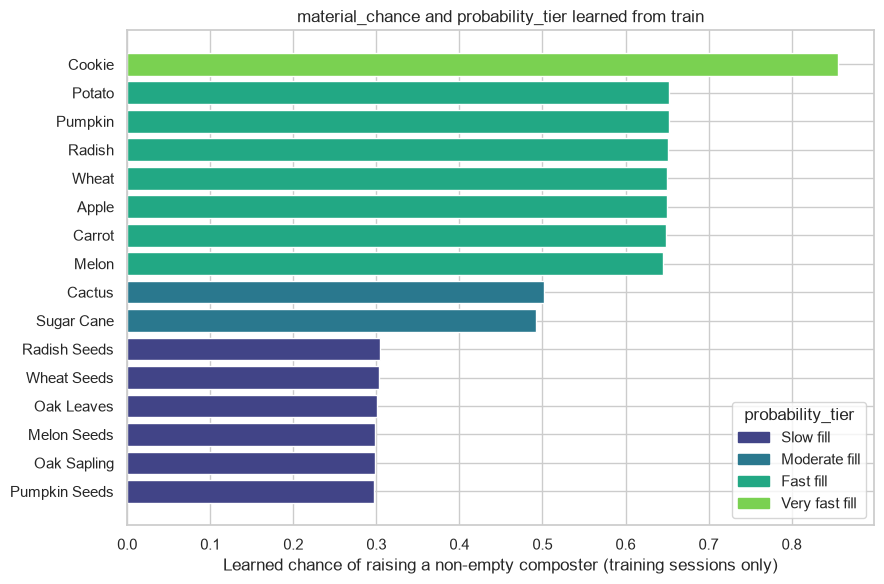

In [11]:
fig, ax = plt.subplots(figsize=(9, 6))
palette = dict(zip(TIER_ORDER, sns.color_palette("viridis", len(TIER_ORDER))))
plot_data = learned.sort_values("material_chance (train)")
ax.barh(plot_data.index, plot_data["material_chance (train)"],
        color=[palette[t] for t in plot_data["probability_tier (train)"]])
ax.set_xlabel("Learned chance of raising a non-empty composter (training sessions only)")
ax.set_title("material_chance and probability_tier learned from train")
ax.legend(handles=[Patch(color=palette[t], label=t) for t in TIER_ORDER], title="probability_tier", loc="lower right")
plt.tight_layout()
plt.show()

In [12]:
fe_train[["session_id", "material", "attempt_number", "composter_empty", "material_chance", "probability_tier"]].head(8)

,session_id,material,attempt_number,composter_empty,material_chance,probability_tier
0,0,Apple,1,1,0.649819,Fast fill
1,0,Apple,2,0,0.649819,Fast fill
2,0,Apple,3,0,0.649819,Fast fill
3,0,Apple,4,0,0.649819,Fast fill
4,0,Apple,5,0,0.649819,Fast fill
5,0,Apple,6,0,0.649819,Fast fill
6,0,Apple,7,0,0.649819,Fast fill
7,0,Apple,8,0,0.649819,Fast fill


**Interpretation.**
- Learned on the 38,400 training sessions alone, the chances fall at ≈ 0.85, 0.65, 0.50 and 0.30, and the largest gaps
  split the materials into the same 4 tiers as the EDA (Cookie | the 65% crops and Radish | Cactus, Sugar Cane | seeds,
  leaves, sapling). The tier structure is therefore stable, but here it is **derived from training data only**.
- `Sugar Cane` keeps a chance slightly below 0.50 because its anomalous stretch is kept (decision D11); the gap to the
  next tier is large, so its tier is not affected.
- In the sample rows, the first attempt of the session has `composter_empty = 1`; the per-material columns are
  constant within a material, as expected for a lookup.

### Candidate rejected: `is_seed`

`is_seed` (material name contains "Seed") is checked on the **training** attempts only. If it carried information
beyond the tier, seeds and non-seeds inside the same tier would succeed at different rates.

In [13]:
is_seed_check = (
    fe_train.loc[fe_train["composter_empty"] == 0]
    .assign(is_seed=lambda d: d["material"].str.contains("Seed").astype(int),
            level_increased=y_train[fe_train["composter_empty"] == 0])
    .groupby(["probability_tier", "is_seed"])
    .agg(n_attempts=("level_increased", "size"), success_rate=("level_increased", "mean"))
)
is_seed_check.round(3)

n_attempts  success_rate
probability_tier is_seed                          
Fast fill        0            155104         0.650
Moderate fill    0             57945         0.497
Slow fill        0             96057         0.300
                 1            191507         0.301
Very fast fill   0             16815         0.856

**Interpretation.** Seeds only exist inside the "Slow fill" tier, and there they succeed at the same rate as
`Oak Leaves` / `Oak Sapling` (≈ 0.30 vs ≈ 0.30, with tens of thousands of attempts each). `is_seed` is a deterministic
function of `material` and adds no separation within tiers, so it is **excluded** — keeping it would only duplicate
evidence that `material` (or its tier) already carries.

# 8. Column Groups

**Motivation.** Every column that reaches the model has to be in an explicit group with a known treatment, and every
column that must not reach it has to be listed with the reason.

In [14]:
NOMINAL_FEATURES = ["material"]                 # 16 unordered categories
ORDINAL_FEATURES = ["probability_tier"]         # 4 ordered levels (TIER_ORDER), learned on train
BINARY_FEATURES = ["composter_empty"]           # 0/1 rule
NUMERIC_FEATURES = ["material_chance"]          # probability in (0, 1), learned on train

EXCLUDED_COLUMNS = {
    "session_id": "identifier; used only to keep sessions intact in the split",
    "attempt_number": "synthetic order inside the session; its only real part (== 1) is composter_empty",
    "trial_id": "identifier (row position in the raw file); never enters X",
    "items_used": "final session length = future information; never enters X",
    "log_items_used / quick_fill_*": "derived from items_used = future information; not created",
    "is_seed": "redundant with material / probability_tier (Section 7)",
}

# Three alternative representations of the material; composter_empty is in all of them.
REPRESENTATIONS = {
    "material": {"nominal": NOMINAL_FEATURES, "binary": BINARY_FEATURES},
    "tier": {"ordinal": ORDINAL_FEATURES, "binary": BINARY_FEATURES},
    "chance": {"numeric": NUMERIC_FEATURES, "binary": BINARY_FEATURES},
}
DEFAULT_REPRESENTATION = "material"

pd.DataFrame(
    [(c, "nominal") for c in NOMINAL_FEATURES] + [(c, "ordinal") for c in ORDINAL_FEATURES]
    + [(c, "binary") for c in BINARY_FEATURES] + [(c, "numeric") for c in NUMERIC_FEATURES]
    + [(c, f"EXCLUDED - {why}") for c, why in EXCLUDED_COLUMNS.items()],
    columns=["column", "group / reason"],
)

,column,group / reason
0,material,nominal
1,probability_tier,ordinal
2,composter_empty,binary
3,material_chance,numeric
4,session_id,EXCLUDED - identifier; used only to keep sessi...
5,attempt_number,EXCLUDED - synthetic order inside the session;...
6,trial_id,EXCLUDED - identifier (row position in the raw...
7,items_used,EXCLUDED - final session length = future infor...
8,log_items_used / quick_fill_*,EXCLUDED - derived from items_used = future in...
9,is_seed,EXCLUDED - redundant with material / probabili...


**Interpretation.** Only four columns can reach a model, and never all at once: `material`, `probability_tier`
and `material_chance` are three encodings of the same information, so each representation uses exactly **one** of
them plus `composter_empty`. This avoids feeding exactly redundant columns to the same model. `material` (one-hot) is
the default because it makes no assumption about how materials group; `tier` and `chance` are the lower-dimensional
candidates the modeling notebook must compare against it.

# 9. Preprocessing by Variable Type

| Group | Transformation | Why |
|---|---|---|
| nominal (`material`) | `OneHotEncoder(handle_unknown="ignore")` | no order between materials; 16 levels is low cardinality; an unseen label becomes an all-zero row instead of an error. No rare-category grouping: every material has 2,400 training sessions |
| ordinal (`probability_tier`) | `OrdinalEncoder` with the explicit order `TIER_ORDER` | the tiers are ordered by chance; the order is fixed by the domain, not learned alphabetically |
| binary (`composter_empty`) | passthrough | already 0/1; scaling or encoding would change nothing useful |
| numeric (`material_chance`) | logit, then `StandardScaler` | a probability acts on the log-odds scale of a logistic model; the scaler is fitted on train only |
| any group | **no imputer** | validation (Section 5) guarantees no missing values, and the features are lookups that always produce a value; an imputer would have nothing to learn |

In [15]:
def logit(x):
    x = np.clip(np.asarray(x, dtype=float), 1e-6, 1 - 1e-6)
    return np.log(x / (1 - x))


GROUP_TRANSFORMERS = {
    "nominal": lambda: OneHotEncoder(handle_unknown="ignore", sparse_output=False),
    "ordinal": lambda: OrdinalEncoder(categories=[TIER_ORDER]),
    "binary": lambda: "passthrough",
    "numeric": lambda: Pipeline([
        ("logit", FunctionTransformer(logit, feature_names_out="one-to-one")),
        ("scale", StandardScaler()),
    ]),
}
print("Per-type transformers:", list(GROUP_TRANSFORMERS))

Per-type transformers: ['nominal', 'ordinal', 'binary', 'numeric']


# 10. ColumnTransformer and Full Pipeline

**Motivation.** The whole path from the raw attempt columns to the model input has to be one object, so that the
modeling notebook can fit it inside each cross-validation fold and apply it to test without any manual step:

```text
X (session_id, material, attempt_number)
  → composter_empty      (stateless rule)
  → material_stats       (material_chance, probability_tier; learned on train)
  → ColumnTransformer    (encode / scale the chosen representation; remainder="drop")
  → [model — next notebook]
```

`remainder="drop"` is what removes `session_id`, `attempt_number` and every column not chosen by the representation:
nothing reaches the model unless a group names it.

In [16]:
def build_preprocessing_pipeline(representation=DEFAULT_REPRESENTATION):
    """Feature engineering + per-type preprocessing for one representation of the material."""
    if representation not in REPRESENTATIONS:
        raise ValueError(f"Unknown representation {representation!r}; choose from {list(REPRESENTATIONS)}")
    columns = ColumnTransformer(
        [(group, GROUP_TRANSFORMERS[group](), cols) for group, cols in REPRESENTATIONS[representation].items()],
        remainder="drop",
        verbose_feature_names_out=True,
    )
    return Pipeline([
        ("composter_empty", FunctionTransformer(add_composter_empty, feature_names_out=composter_empty_names)),
        ("material_stats", MaterialStatsEncoder(n_tiers=4)),
        ("columns", columns),
    ])


preprocessor = build_preprocessing_pipeline(DEFAULT_REPRESENTATION)
preprocessor

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('composter_empty', ...), ('material_stats', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"func func: callable, default=NoneThe callable to use for the transformation. This will be passedthe same arguments as transform, with args and kwargs forwarded.If func is None, then func will be the identity function.",<function add...002D41D459300>
,"feature_names_out feature_names_out: callable, 'one-to-one' or None, default=NoneDetermines the list of feature names that will be returned by the`get_feature_names_out` method. If it is 'one-to-one', then the outputfeature names will be equal to the input feature names. If it is acallable, then it must take two positional arguments: this`FunctionTransformer` (`self`) and an array-like of input feature names(`input_features`). It must return an array-like of output featurenames. The `get_feature_names_out` method is only defined if`feature_names_out` is not None.See ``get_feature_names_out`` for more details... versionadded:: 1.1",<function com...002D47B8A79C0>
,"inverse_func inverse_func: callable, default=NoneThe callable to use for the inverse transformation. This will bepassed the same arguments as inverse transform, with args andkwargs forwarded. If inverse_func is None, then inverse_funcwill be the identity function.",None
,"validate validate: bool, default=FalseIndicate that the input X array should be checked before calling``func``. The possibilities are:- If False, there is no input validation.- If True, then X will be converted to a 2-dimensional NumPy array or sparse matrix. If the conversion is not possible an exception is raised... versionchanged:: 0.22 The default of ``validate`` changed from True to False.",False
,"accept_sparse accept_sparse: bool, default=FalseIndicate that func accepts a sparse matrix as input. If validate isFalse, this has no effect. Otherwise, if accept_sparse is false,sparse matrix inputs will cause an exception to be raised.",False
,"check_inverse check_inverse: bool, default=TrueWhether to check that or ``func`` followed by ``inverse_func`` leads tothe original inputs. It can be used for a sanity check, raising awarning when the condition is not fulfilled... versionadded:: 0.20",True
,"kw_

In [17]:
Xt_train = preprocessor.fit_transform(X_train, y_train)
feature_names = preprocessor.get_feature_names_out()
print(f"Representation '{DEFAULT_REPRESENTATION}': X_train {X_train.shape} -> {Xt_train.shape}")
pd.DataFrame(Xt_train, columns=feature_names).head()

Representation 'material': X_train (555828, 3) -> (555828, 17)


,nominal__material_Apple,nominal__material_Cactus,nominal__material_Carrot,nominal__material_Cookie,nominal__material_Melon,nominal__material_Melon Seeds,nominal__material_Oak Leaves,nominal__material_Oak Sapling,nominal__material_Potato,nominal__material_Pumpkin,nominal__material_Pumpkin Seeds,nominal__material_Radish,nominal__material_Radish Seeds,nominal__material_Sugar Cane,nominal__material_Wheat,nominal__material_Wheat Seeds,binary__composter_empty
0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
1,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


**Interpretation.** The default pipeline turns the 3 raw columns into 17 model inputs: 16 one-hot columns for
`material` and the `composter_empty` flag. Everything that learns from data (`MaterialStatsEncoder`, the encoders,
the scaler) is fitted by a single `fit` call on the training attempts. In the modeling notebook this pipeline goes
inside cross-validation, so it is re-fitted on the training part of each fold — with folds grouped by `session_id`
(e.g. `StratifiedGroupKFold`) for the same reason as the train/test split. Section 11 checks the result.

# 11. Structural Verifications (train only)

**Motivation.** A pipeline that runs is not necessarily correct. Using **only the training data**, the checks below
confirm that it keeps every observation, produces no missing or infinite values, never lets an excluded column through,
does not modify its input, and is deterministic. Each representation gets a fresh, unfitted pipeline.

In [18]:
X_train_before, y_train_before = X_train.copy(deep=True), y_train.copy(deep=True)
FORBIDDEN_IN_OUTPUT = ["session_id", "attempt_number", "trial_id", "items_used", "is_seed"]

fitted_preprocessors, verification_rows = {}, []
for representation in REPRESENTATIONS:
    pipe = build_preprocessing_pipeline(representation)
    Xt = pipe.fit_transform(X_train, y_train)
    names = list(pipe.get_feature_names_out())
    leaked = [col for col in FORBIDDEN_IN_OUTPUT if any(col in name for name in names)]

    check(Xt.shape[0] == len(X_train), f"{representation}: same number of rows as X_train")
    check(not np.isnan(Xt).any(), f"{representation}: no NaN in the output")
    check(np.isfinite(Xt).all(), f"{representation}: no infinite values in the output")
    check(not leaked, f"{representation}: excluded columns do not reach the model (found: {leaked})")
    check(np.array_equal(Xt, build_preprocessing_pipeline(representation).fit_transform(X_train, y_train)),
          f"{representation}: re-fitting gives identical output (deterministic)")

    fitted_preprocessors[representation] = pipe
    verification_rows.append({
        "representation": representation,
        "rows in": len(X_train), "columns in": X_train.shape[1],
        "rows out": Xt.shape[0], "columns out": Xt.shape[1],
        "NaN": int(np.isnan(Xt).sum()), "inf": int(np.isinf(Xt).sum()),
        "output features": ", ".join(names) if len(names) <= 3 else f"{len(names)} columns ({names[0]}, ...)",
    })

check(X_train.equals(X_train_before) and y_train.equals(y_train_before),
      "X_train and y_train are unchanged after fitting all pipelines")
print("All structural checks passed for every representation; X_train / y_train were not modified.")
pd.DataFrame(verification_rows).set_index("representation")

All structural checks passed for every representation; X_train / y_train were not modified.


,rows in,columns in,rows out,columns out,NaN,inf,output features
representation,,,,,,,
material,555828,3,555828,17,0,0,"17 columns (nominal__material_Apple, ...)"
tier,555828,3,555828,2,0,0,"ordinal__probability_tier, binary__composter_e..."
chance,555828,3,555828,2,0,0,"numeric__material_chance, binary__composter_empty"


**Interpretation.** All three pipelines keep the 555,828 training attempts, produce no NaN or infinite values,
drop the identifier and the synthetic order, give the same output when re-fitted, and leave `X_train` / `y_train`
untouched (every transformer works on a copy). The largest increase in dimensionality is the default `material`
representation: from 3 raw columns to 17 (16 one-hot indicators + `composter_empty`). That is a small, fixed increase
— the number of materials does not grow with the data — so it poses no dimensionality problem. `tier` and `chance`
compress the material into a single column.

### What the model will see

A representative sample of the default representation — one empty and one non-empty attempt for a few materials —
together with the inputs they came from, and a sanity check of the one-hot block.

In [19]:
default_pipe = fitted_preprocessors[DEFAULT_REPRESENTATION]
Xt_default = pd.DataFrame(default_pipe.transform(X_train), columns=default_pipe.get_feature_names_out(),
                          index=X_train.index)
check(Xt_default.filter(like="nominal__material_").sum(axis=1).eq(1).all(),
      "exactly one material indicator is active in every training row")

sample_idx = (
    X_train.assign(empty=X_train["attempt_number"].eq(1))
    .loc[lambda d: d["material"].isin(["Cookie", "Cactus", "Wheat Seeds"])]
    .groupby(["material", "empty"]).head(1).index
)
active_material = Xt_default.filter(like="nominal__material_").idxmax(axis=1).str.replace("nominal__material_", "")
pd.DataFrame({
    "material (input)": X_train.loc[sample_idx, "material"],
    "attempt_number (input)": X_train.loc[sample_idx, "attempt_number"],
    "active one-hot column": active_material.loc[sample_idx],
    "binary__composter_empty": Xt_default.loc[sample_idx, "binary__composter_empty"],
    "level_increased (target)": y_train.loc[sample_idx],
})

,material (input),attempt_number (input),active one-hot column,binary__composter_empty,level_increased (target)
24560,Cactus,1,Cactus,1.0,1
24561,Cactus,2,Cactus,0.0,0
80245,Cookie,1,Cookie,1.0,1
80246,Cookie,2,Cookie,0.0,1
505983,Wheat Seeds,1,Wheat Seeds,1.0,1
505984,Wheat Seeds,2,Wheat Seeds,0.0,1


In [20]:
tier_pipe, chance_pipe = fitted_preprocessors["tier"], fitted_preprocessors["chance"]
encoded_by_material = pd.DataFrame({
    "material": X_train["material"],
    "ordinal__probability_tier": tier_pipe.transform(X_train)[:, 0],
    "numeric__material_chance (scaled logit)": chance_pipe.transform(X_train)[:, 0],
}).drop_duplicates("material").set_index("material").sort_values("ordinal__probability_tier")
encoded_by_material.round(3)

,ordinal__probability_tier,numeric__material_chance (scaled logit)
material,,
Oak Leaves,0.0,-0.839
Oak Sapling,0.0,-0.853
Melon Seeds,0.0,-0.852
Pumpkin Seeds,0.0,-0.864
Radish Seeds,0.0,-0.820
Wheat Seeds,0.0,-0.823
Sugar Cane,1.0,0.231
Cactus,1.0,0.285
Radish,2.0,1.097


**Interpretation.** Each input row maps to exactly one active material indicator plus the empty-composter flag;
the target is not among the outputs. In the alternative representations the ordinal tier runs 0 (Slow fill) to 3
(Very fast fill) in the domain order, and the scaled logit of the chance preserves the same ranking of materials while
keeping the within-tier differences that the tier discards.

### Behavior on new inputs

The pipeline must also work on rows it has never seen — including a material that was not in training. This uses a
small **hand-made** example (not the test set): a known material on an empty and a non-empty composter, and an unknown
item (`Bread`).

In [21]:
new_attempts = pd.DataFrame({
    "session_id": [900_001, 900_001, 900_002],
    "material": ["Wheat Seeds", "Wheat Seeds", "Bread"],
    "attempt_number": [1, 2, 1],
})
new_view = new_attempts.copy()
for representation, pipe in fitted_preprocessors.items():
    out = pd.DataFrame(pipe.transform(new_attempts), columns=pipe.get_feature_names_out())
    if representation == "material":
        new_view["material: active one-hot columns"] = out.filter(like="nominal__material_").sum(axis=1).astype(int)
        new_view["material: composter_empty"] = out["binary__composter_empty"].astype(int)
    elif representation == "tier":
        new_view["tier: ordinal"] = out["ordinal__probability_tier"]
    else:
        new_view["chance: scaled logit"] = out["numeric__material_chance"].round(3)
new_view

,session_id,material,attempt_number,material: active one-hot columns,material: composter_empty,tier: ordinal,chance: scaled logit
0,900001,Wheat Seeds,1,1,1,0.0,-0.823
1,900001,Wheat Seeds,2,1,0,0.0,-0.823
2,900002,Bread,1,0,1,1.0,-0.016


**Interpretation.** Known materials are encoded as during training. The unknown item does not crash any
pipeline: in the `material` representation it becomes an all-zero material block (`handle_unknown="ignore"`), and in
`tier` / `chance` it receives the overall training chance and the nearest tier. The `composter_empty` flag still works
for it, which is the correct domain behavior: an empty composter's level rises whatever the item. Unseen materials remain
outside the generalization scenario declared in Section 1; this only shows the pipeline degrades gracefully.

# 12. Conclusions and Handoff to the Modeling Notebook

**Decisions taken**
- The data is rebuilt from the 16 raw files and validated (schema, ranges, uniqueness, missing / infinite values,
  materials, target consistency).
- The split is made on **sessions** — 80/20, stratified by material, seed 42 — and each partition is expanded to
  attempts afterwards, so no session is shared between train and test.
- Features: `composter_empty` (rule), `material_chance` (train-only aggregation), `probability_tier` (train-only
  binning). `is_seed` was evaluated and rejected.
- One pipeline per representation (`material`, `tier`, `chance`), each `composter_empty` + **one** encoding of the
  material, built as `FunctionTransformer → MaterialStatsEncoder → ColumnTransformer(remainder="drop")`.

**Excluded variables:** `session_id` (kept only for grouping), `attempt_number` (synthetic order), `trial_id`,
`items_used` and its derivatives (future information), `is_seed` (redundant).

**Limitations**
- The order of outcomes inside a session is synthetic. The features do not depend on it, but the attempt-level labels
  of the middle attempts are one random realization; per-session counts are exact.
- The EDA was done on all sessions, so the test set has influenced some decisions indirectly (number of tiers,
  mechanism, anomaly flag). No transformation in this notebook was decided or fitted with test data.
- With `material` and `composter_empty` as the only legitimate inputs, the best achievable model is essentially the
  per-material chance plus the empty-composter rule; probability quality (log loss, Brier score, calibration) will be
  more informative than accuracy.
- The `Sugar Cane` stretch (trial_id 339–398) is kept; it slightly lowers that material's learned chance (0.492).

**Hypotheses for the modeling notebook**
1. `material` (one-hot) vs. `probability_tier` vs. `material_chance` — compared out of sample with cross-validation
   **grouped by `session_id`** (e.g. `StratifiedGroupKFold`), the pipeline re-fitted inside each fold.
2. Effect of `composter_empty`: the same models with and without it.
3. Sensitivity to the `Sugar Cane` anomaly: results with and without the flagged sessions in training.
4. Baselines to beat: majority class; per-material training rate; the rule "1 if the composter is empty, else the
   material's training chance".

**Objects the modeling notebook will use** (re-created there with the same code and constants, since a notebook
cannot depend on variables from another one):
- `RANDOM_STATE = 42`, `TEST_SIZE = 0.20`, `RAW_FILES`, `load_sessions`, `check` and the validation rules;
- the session-level split (`train_test_split` on sessions, stratified by material) and `expand_sessions_to_attempts`
  with the same seeds, giving the same `X_train`, `y_train`, `X_test`, `y_test`;
- `add_composter_empty`, `MaterialStatsEncoder`, `REPRESENTATIONS`, `build_preprocessing_pipeline(representation)`;
- `session_id` from the training attempts as the `groups` argument for cross-validation.

`X_test` / `y_test` were created and checked for structure only; they were never transformed or explored here and stay
reserved for the final evaluation. No model was trained and no hyperparameter was tuned in this notebook.